# [14.6] Sudoku and Constraint World Models (exercises)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part6_sudoku_transformers/14.6_Sudoku_and_Constraint_World_Models_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter14_jepa_world_models/exercises/part6_sudoku_transformers/14.6_Sudoku_and_Constraint_World_Models_solutions.ipynb)**

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

# Introduction

Consider the row `1, 0, 3, 4`. The missing digit is 2. But on a real Sudoku board, a move must satisfy its column and its 2×2 box as well. **Does an internal “candidate 2” representation merely predict a move, or does changing it actually change the move?**

By the end of this notebook, you will have shown that a visible candidate representation mediates a constrained attention model's choice on 4×4 Sudoku, by patching that representation and checking the resulting move against an independent legality oracle. The primary result is a board-and-candidate intervention figure with legal/illegal outcomes, supported by a solving trajectory and an untrained control.

The default organism is small enough to inspect: uniform attention over Sudoku peers, clue-value features, and a learned four-output candidate head. The peer graph is **given as an architectural prior**. We do not claim it discovered row/column/box rules. A short, fixed CPU readout fit is ordinary lesson execution, not a native large-model experiment. It trains candidate prediction, then uses a visible naked-single policy. Solving arbitrary Sudoku with an unconstrained learned transformer remains pending.

Prerequisites: attention from 1.1, probes and causal interventions from chapter 1/11, and Boolean broadcasting. Zeros denote blanks; digits are 1–4. No downloads or GPU are used.

## Content & Learning Objectives

### 1️⃣ Turn a board into constraints

> ##### Learning Objectives
>
> - Construct Sudoku peers, clue tokens and independently checked candidate sets for a 4×4 board.

### 2️⃣ A tiny attention model with visible state

> ##### Learning Objectives
>
> - Implement geometric attention and train a small candidate readout, keeping its architectural prior explicit.

### 3️⃣ From a candidate to a legal trajectory

> ##### Learning Objectives
>
> - Extract naked singles, apply moves and compare a constraint rollout with an untrained control and exact search.

### 4️⃣ Causally edit a candidate representation

> ##### Learning Objectives
>
> - Patch a candidate state, measure the resulting move and check whether it violates the original puzzle.

## Setup code

This study edition uses tiny CPU fixtures: no network, pretrained checkpoint, GPU or additional installation.

In [ ]:
from pathlib import Path
import sys
import itertools
import numpy as np
import torch as t
import torch.nn.functional as F
import matplotlib.pyplot as plt
chapter = "chapter14_jepa_world_models"
section = "part6_sudoku_transformers"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.insert(0, str(exercises_dir))
import part6_sudoku_transformers.tests as tests
MAIN = __name__ == "__main__"
device = t.device("cpu")
np.set_printoptions(precision=4, suppress=True)

# 1️⃣ Turn a board into constraints

> ##### Learning Objectives
>
> - Construct Sudoku peers, clue tokens and independently checked candidate sets for a 4×4 board.

Flatten a board in row-major order: cell $(r,c)$ has index $4r+c$. Two distinct cells are peers if they share a row, column or 2×2 box. Each cell has seven distinct peers; do not count a shared row and box twice. A candidate digit is absent from all current peers. Filled cells get **no candidates**, because we do not make a move on them.

Keep three objects distinct: the board is the current state; candidate sets are a derived state; and a completed solution is a global constraint witness. A locally allowed digit need not extend to any full solution. We build an exact tiny solver later to expose that difference. No probe gets to look at that solver's answer while constructing candidates.

### Exercise - implement `sudoku_peers`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return a Boolean `(16,16)` peer matrix. It is symmetric, has zero diagonal, and treats cells sharing multiple units as one peer. This matrix will be the attention mask, so a geometric mistake here becomes a model mistake rather than a plotting error.

In [ ]:
def sudoku_peers():
    raise NotImplementedError()


tests.test_sudoku_peers(sudoku_peers)

<details><summary>Hint</summary>

Build row, column and box relations, take their union and remove the diagonal.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_sudoku_peers passed!`. Each of the 16 cells attends to seven unique peers.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def sudoku_peers():
    row, col = np.divmod(np.arange(16), 4)
    same_row = row[:,None] == row[None,:]
    same_col = col[:,None] == col[None,:]
    same_box = (row[:,None]//2 == row[None,:]//2) & (col[:,None]//2 == col[None,:]//2)
    return (same_row | same_col | same_box) & ~np.eye(16,dtype=bool)
```
</details>

### Exercise - implement `clue_tokens`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Encode each digit as one of four feature channels and blanks as zero. Input ends in `(4,4)`; output ends in `(16,4)`. Use a temporary five-class encoding then remove the blank channel. A blank must not look like digit one.

In [ ]:
def clue_tokens(boards):
    raise NotImplementedError()


tests.test_clue_tokens(clue_tokens)

<details><summary>Hint</summary>

Keep the batch axes while flattening only row and column.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_clue_tokens passed!`. Digit 3 maps to `[0,0,1,0]`; a blank maps to all zeros.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def clue_tokens(boards):
    boards = t.as_tensor(boards, dtype=t.long)
    flat = boards.reshape(*boards.shape[:-2],16)
    return F.one_hot(flat,num_classes=5)[...,1:].to(t.float32)
```
</details>

### Exercise - implement `legal_candidates`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the exact locally legal candidate matrix `(16,4)`. Filled cells must be false in every channel. This function supplies the transparent training target. The independent test below checks candidates by trying each digit and checking units directly, so an attention-mask bug cannot validate itself.

In [ ]:
def legal_candidates(board):
    raise NotImplementedError()


tests.test_legal_candidates(legal_candidates)

<details><summary>Hint</summary>

Use the set of visible peer digits; zero is never a candidate digit.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_legal_candidates passed!`. The one-blank board has exactly one candidate: cell `(0,1)` digit 2.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def legal_candidates(board):
    board=np.asarray(board,dtype=int)
    out=np.zeros((16,4),dtype=bool)
    flat=board.ravel();peers=sudoku_peers()
    for cell in range(16):
        if flat[cell] == 0:
            forbidden=set(flat[peers[cell]])
            out[cell]=[digit not in forbidden for digit in range(1,5)]
    return out
```
</details>

### Exercise - implement `valid_partial`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Check all rows, columns and boxes for repeated nonzero digits. Return a Python Boolean. This validator is used after interventions; accepting a donor candidate representation does not authorize changing the puzzle constraints themselves.

In [ ]:
def valid_partial(board):
    raise NotImplementedError()


tests.test_valid_partial(valid_partial)

<details><summary>Hint</summary>

Remove zeros before counting unique digits in every unit.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_valid_partial passed!`. The genuine blank board is valid; a repeated digit in only a box must still fail.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def valid_partial(board):
    board=np.asarray(board,dtype=int)
    if board.shape != (4,4) or np.any((board<0)|(board>4)):
        return False
    units=list(board)+list(board.T)+[board[r:r+2,c:c+2].ravel() for r in (0,2) for c in (0,2)]
    return all(len(v[v!=0])==len(set(v[v!=0])) for v in units)
```
</details>

In [ ]:
solved=np.array([[1,2,3,4],[3,4,1,2],[2,1,4,3],[4,3,2,1]])
puzzle=solved.copy()
puzzle.ravel()[[0,1,4,6,9,10,12,15]]=0
print("Cold-open puzzle:\n",puzzle)
print("Candidate counts:\n",legal_candidates(puzzle).sum(1).reshape(4,4))

## Summary of 1️⃣

Candidate sets are an explicit intermediate representation with independently checkable meaning. They encode local exclusions, not a hidden completed board.

# 2️⃣ A tiny attention model with visible state

> ##### Learning Objectives
>
> - Implement geometric attention and train a small candidate readout, keeping its architectural prior explicit.

A masked attention head can aggregate peer clues. Set every allowed query/key logit to zero and every forbidden logit to $-\infty$. Softmax therefore assigns weight $1/7$ to each peer. Values are four-dimensional digit indicators. Multiplying the head output by seven gives the number of peer occurrences of each digit:
$$u_i = 7\sum_{j\in\mathrm{peers}(i)}\alpha_{ij}\,\mathrm{onehot}(b_j).$$
A legal candidate has count zero. A small affine head maps the four counts to four logits; the target is the legal-candidate indicator on blank cells. We train this readout only. The attention pattern and clue values are fixed, transparent transformer components. This architecture inserts much of the algorithm by hand, so success does not demonstrate learned Sudoku reasoning.

The 96-board fitting fixture uses 24 digit permutations of a valid board, each with four deterministic blank masks. A 24-board check fixture uses a different mask. Both are public constructed examples based on the same solution orbit. They are not independent generalization data. Fit 120 Adam steps, learning rate `.08`, CPU, fixed initialization. This is a small classroom fitting recipe, not a hyperparameter sweep.

### Exercise - implement `peer_attention`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the full masked attention aggregation, returning count features and the attention matrix. The input ends in `(16,4)`. Multiply by the actual peer count to undo mean pooling. Keep Torch gradients through value features, permitting later causal edits or learned value maps.

In [ ]:
def peer_attention(tokens, peers):
    raise NotImplementedError()


tests.test_peer_attention(peer_attention)

<details><summary>Hint</summary>

Use `einsum` for query-cell × key-cell attention against key-cell × digit values.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_peer_attention passed!`. In a one-neighbor ring, each cell receives exactly its next neighbor’s four features.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def peer_attention(tokens, peers):
    mask=t.as_tensor(peers,dtype=t.bool,device=tokens.device)
    logits=t.zeros((16,16),dtype=tokens.dtype,device=tokens.device).masked_fill(~mask,-t.inf)
    attention=logits.softmax(dim=-1)
    counts=t.einsum("ij,...jd->...id",attention,tokens)*mask.sum(-1)[:,None]
    return counts, attention
```
</details>

### Exercise - implement `candidate_bce`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Compute mean binary cross-entropy over blank cells and all four digits. Filled cells are ignored. A blank cell may have multiple legal digits, so softmax cross-entropy would use the wrong target space. Keep the output differentiable.

In [ ]:
def candidate_bce(logits, candidate_targets, blank_mask):
    raise NotImplementedError()


tests.test_candidate_bce(candidate_bce)

<details><summary>Hint</summary>

Mask per-digit losses before summing and divide by the number of supervised bits.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_candidate_bce passed!`. Zero logits give `log(2)`; the filled cell has no gradient.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def candidate_bce(logits, candidate_targets, blank_mask):
    per_digit=F.binary_cross_entropy_with_logits(logits,candidate_targets.to(logits.dtype),reduction="none")
    mask=blank_mask.to(logits.dtype)[...,None]
    return (per_digit*mask).sum()/(mask.sum()*logits.shape[-1])
```
</details>

### Exercise - implement `train_candidate_head`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Fit the tiny candidate head and retain its full loss curve. `counts` and targets are fixed fixture tensors; only the 20 head parameters train. Starting from zero makes the untrained control predict 0.5 for every digit. Explain why this is supervised candidate learning, not discovered constraint extraction.

In [ ]:
def train_candidate_head(counts, targets, blanks, steps=120):
    raise NotImplementedError()


tests.test_train_candidate_head(train_candidate_head)

<details><summary>Hint</summary>

The loss has independent sigmoid outputs; optimize every head parameter.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_train_candidate_head passed!`. The symmetric four-case fixture learns all four correct candidate bits and reduces loss by at least fivefold.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def train_candidate_head(counts, targets, blanks, steps=120):
    head=t.nn.Linear(4,4,device="cpu")
    with t.no_grad():
        head.weight.zero_();head.bias.zero_()
    optimizer=t.optim.Adam(head.parameters(),lr=.08)
    losses=[]
    for _ in range(steps):
        optimizer.zero_grad()
        loss=candidate_bce(head(counts),targets,blanks)
        loss.backward();optimizer.step();losses.append(float(loss.detach()))
    return head,np.array(losses)
```
</details>

In [ ]:
# Limit CPU threading for this tiny dense fit; preserve the caller's thread count.
previous_threads=t.get_num_threads();t.set_num_threads(1)
fitting=[];checking=[]
masks=[[0,1,4,6,9,10,12,15],[0,2,5,7,8,11,13,14],[1,3,4,7,8,10,12,14],[0,3,5,6,9,11,12,15]]
for permutation in itertools.permutations([1,2,3,4]):
    mapped=np.array([0,*permutation])[solved]
    for mask in masks:
        b=mapped.copy();b.ravel()[mask]=0;fitting.append(b)
    b=mapped.copy();b.ravel()[[0,2,4,5,7,9,11,14]]=0;checking.append(b)
fitting,checking=np.array(fitting),np.array(checking)
peers=sudoku_peers()
train_counts,attention=peer_attention(clue_tokens(fitting),peers)
train_targets=t.tensor(np.array([legal_candidates(b) for b in fitting]))
train_blanks=t.tensor(fitting.reshape(-1,16)==0)
head,losses=train_candidate_head(train_counts,train_targets,train_blanks)
check_counts,_=peer_attention(clue_tokens(checking),peers)
check_targets=t.tensor(np.array([legal_candidates(b) for b in checking]))
check_blanks=t.tensor(checking.reshape(-1,16)==0)
with t.no_grad():
    predicted=(head(check_counts)>0)&check_blanks[...,None]
check_bit_accuracy=float((predicted[check_blanks]==check_targets[check_blanks]).float().mean())
print("candidate-bit accuracy on public changed-mask check:",check_bit_accuracy)
print("loss initial/final:",round(float(losses[0]),6),round(float(losses[-1]),6))
t.set_num_threads(previous_threads)


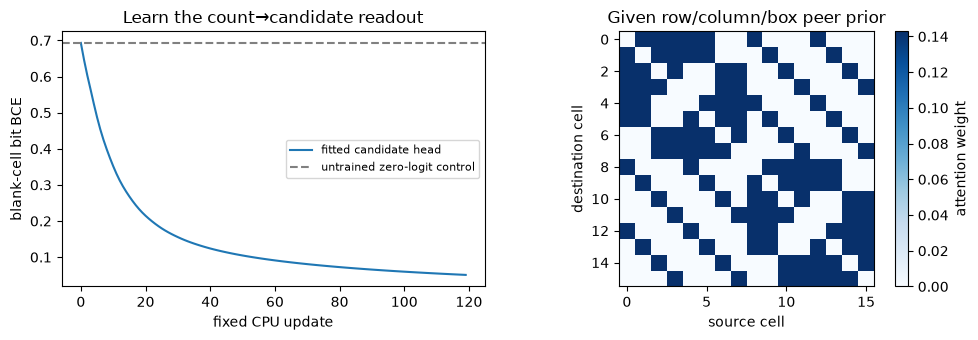

In [ ]:
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].plot(losses,label="fitted candidate head");axs[0].axhline(np.log(2),ls="--",color="grey",label="untrained zero-logit control")
axs[0].set(xlabel="fixed CPU update",ylabel="blank-cell bit BCE",title="Learn the count→candidate readout");axs[0].legend(fontsize=8)
im=axs[1].imshow(attention.numpy(),cmap="Blues");fig.colorbar(im,ax=axs[1],label="attention weight")
axs[1].set(xlabel="source cell",ylabel="destination cell",title="Given row/column/box peer prior")
fig.tight_layout();plt.show()

## Summary of 2️⃣

The architecture computes peer counts, while training learns their candidate readout. The learned head is an inspectable model component, and the geometry is an explicit built-in prior. We must not call that prior a discovered circuit.

# 3️⃣ From a candidate to a legal trajectory

> ##### Learning Objectives
>
> - Extract naked singles, apply moves and compare a constraint rollout with an untrained control and exact search.

A **naked single** is a blank cell with exactly one remaining candidate. Make one move at a time, recompute candidate representations and stop when solved, contradicted or stalled. If multiple singles exist, choose the earliest flattened cell. This frozen tie rule makes the trajectory reproducible.

We use the learned head's positive logits to define predicted candidate bits. The untrained control uses zero logits; with the strict `>0` rule it proposes no candidate and stalls immediately. An exact recursive solver provides a global completion witness independently of the learned head. It is a baseline/oracle, not the model's policy. A board with no naked singles can still have solutions; reporting “unsolved by this policy” is different from “unsatisfiable.”

### Exercise - implement `naked_single_move`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Return the first single `(flat_cell,digit)`, or `None` if no single exists. Candidate entries are Boolean and digits are one-based. Ignore filled cells even if their representation is corrupted.

In [ ]:
def naked_single_move(candidates, board):
    raise NotImplementedError()


tests.test_naked_single_move(naked_single_move)

<details><summary>Hint</summary>

Count true entries along the digit axis before selecting the first eligible cell.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_naked_single_move passed!`. The first eligible single is cell 5, digit 3; a two-candidate cell is not a single.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def naked_single_move(candidates, board):
    blank=np.asarray(board).ravel()==0
    counts=candidates.sum(axis=-1)
    rows=np.flatnonzero(blank & (counts==1))
    if len(rows)==0:
        return None
    cell=int(rows[0]);digit=int(np.flatnonzero(candidates[cell])[0]+1)
    return cell,digit
```
</details>

### Exercise - implement `apply_move`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Apply one proposed move to a copied board. Validate the interface (blank cell and valid digit), but do not silently reject a constraint violation here. We need to observe an illegal move after a causal intervention; `valid_partial` measures it explicitly.

In [ ]:
def apply_move(board, move):
    raise NotImplementedError()


tests.test_apply_move(apply_move)

<details><summary>Hint</summary>

A flattened view of the copied board permits assignment by flat cell index.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_apply_move passed!`. The move changes exactly cell `(1,1)` and preserves the original board.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def apply_move(board, move):
    out=np.array(board,copy=True)
    cell,digit=move
    if out.ravel()[cell] != 0 or digit not in range(1,5):
        raise ValueError("move must fill a blank with a valid digit")
    out.ravel()[cell]=digit
    return out
```
</details>

### Exercise - implement `solve_exact`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Write a complete depth-first constraint solver for 4×4 boards. Try digits in ascending order, return the first completion, and return `None` for contradictions. This oracle need not be efficient for 9×9: it exists to distinguish local policy failure from lack of a solution.

In [ ]:
def solve_exact(board):
    raise NotImplementedError()


tests.test_solve_exact(solve_exact)

<details><summary>Hint</summary>

Recurse only after validating the current partial board.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_solve_exact passed!`. The one-blank puzzle completes with 2; a contradictory clue board has no completion.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def solve_exact(board):
    if not valid_partial(board):
        return None
    blank=np.flatnonzero(np.asarray(board).ravel()==0)
    if not len(blank):
        return np.array(board,copy=True)
    cell=int(blank[0]);candidates=legal_candidates(board)[cell]
    for digit in np.flatnonzero(candidates)+1:
        answer=solve_exact(apply_move(board,(cell,int(digit))))
        if answer is not None:
            return answer
    return None
```
</details>

### Exercise - implement `solve_by_head`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement the complete model-driven trajectory with a fixed move limit. Recompute attention and logits after every move. Stop if the move violates a constraint, retaining the offending state for inspection. Do not replace the learned head with exact candidates in this function.

In [ ]:
def solve_by_head(board, head, limit=16):
    raise NotImplementedError()


tests.test_solve_by_head(solve_by_head)

<details><summary>Hint</summary>

The head takes count features; only the policy converts its positive logits to candidate decisions.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_solve_by_head passed!`. The analytic head solves the one-blank fixture in one move; zero logits stall.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def solve_by_head(board, head, limit=16):
    states=[np.array(board,copy=True)];moves=[]
    for _ in range(limit):
        counts,_=peer_attention(clue_tokens(states[-1]),sudoku_peers())
        with t.no_grad():
            candidates=(head(counts)>0).numpy()
        move=naked_single_move(candidates,states[-1])
        if move is None:
            break
        next_board=apply_move(states[-1],move)
        states.append(next_board);moves.append(move)
        if not valid_partial(next_board):
            break
    return np.array(states),moves
```
</details>


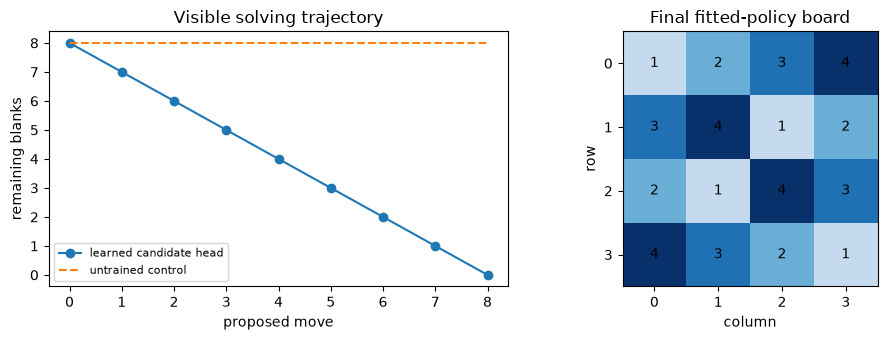

In [ ]:
trajectory,moves=solve_by_head(puzzle,head)
zero_head=t.nn.Linear(4,4)
with t.no_grad():zero_head.weight.zero_();zero_head.bias.zero_()
control_states,control_moves=solve_by_head(puzzle,zero_head)
print("fitted move trajectory:",moves)
print("remaining blanks fitted/untrained:",int((trajectory[-1]==0).sum()),int((control_states[-1]==0).sum()))
print("exact completion exists:",solve_exact(puzzle) is not None)
fig,axs=plt.subplots(1,2,figsize=(10,3.5))
axs[0].plot([(b==0).sum() for b in trajectory],"o-",label="learned candidate head")
axs[0].plot(range(len(trajectory)),np.repeat((puzzle==0).sum(),len(trajectory)),"--",label="untrained control")
axs[0].set(xlabel="proposed move",ylabel="remaining blanks",title="Visible solving trajectory");axs[0].legend(fontsize=8)
axs[1].imshow(trajectory[-1],vmin=0,vmax=4,cmap="Blues")
for r in range(4):
    for c in range(4):axs[1].text(c,r,str(trajectory[-1,r,c]) or ".",ha="center",va="center")
axs[1].set(xticks=range(4),yticks=range(4),xlabel="column",ylabel="row",title="Final fitted-policy board")
fig.tight_layout();plt.show()

## Summary of 3️⃣

The full trajectory is generated from the model's candidate head. A validator and exact solver evaluate the outcome independently. Keeping a failed or stalled trajectory is part of understanding the policy, not an execution failure to hide.

# 4️⃣ Causally edit a candidate representation

> ##### Learning Objectives
>
> - Patch a candidate state, measure the resulting move and check whether it violates the original puzzle.

We now intervene **after** the head and **before** the move policy. The recipient has one blank at `(0,1)` with digit 2 forced. The donor is an all-blank board, where every digit is locally allowed. Patch a donor-derived digit channel into the recipient representation to make digit 1 the only apparent candidate. The move policy will choose it, and the original board validator should reject it.

This is a strong causal claim about the **constructed intermediate candidate interface**: the policy uses those bits. It is not a discovered hidden-state circuit in a naturally trained solver, and an off-manifold representation edit does not establish that a real clue edit has the same effect. A wrong-cell patch supplies a control: if the policy ignores that filled cell, the move should remain 2.

### Exercise - implement `patch_candidate_state`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Replace the target cell’s candidate representation with one selected donor digit bit. Other cells remain unchanged. The donor digit is one-based. This is a deliberately targeted intervention, so report the exact donor and coordinate rather than calling it a generic activation patch.

In [ ]:
def patch_candidate_state(recipient, donor, cell, donor_digit):
    raise NotImplementedError()


tests.test_patch_candidate_state(patch_candidate_state)

<details><summary>Hint</summary>

Clear the chosen recipient row before copying the selected donor bit.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_patch_candidate_state passed!`. The recipient cell changes from candidate 2 to candidate 1; all other rows stay fixed.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def patch_candidate_state(recipient, donor, cell, donor_digit):
    out=np.array(recipient,copy=True)
    out[cell]=False
    out[cell,donor_digit-1]=donor[cell,donor_digit-1]
    return out
```
</details>

### Exercise - implement `candidate_agreement`

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Report exact-set accuracy over blank cells. Bit accuracy can hide an important extra candidate; exact-set agreement requires all four bits to match. The denominator is blank cells only, not every filled cell with an easy all-false target.

In [ ]:
def candidate_agreement(predicted, truth, blanks):
    raise NotImplementedError()


tests.test_candidate_agreement(candidate_agreement)

<details><summary>Hint</summary>

Compare all digit bits within each blank, then average over blanks.

</details>

<details><summary>Expected output</summary>

The immediate semantic fixture should print `All tests in test_candidate_agreement passed!`. One of two blank-cell candidate sets matches exactly, giving .5.

</details>

<details><summary>Help - why this step?</summary>

Implement the stated operation before continuing. Inspect the fixture if the test fails: it is an independent small example, not a comparison with a hidden solution. The following experiment calls this function, so changing it changes the actual result.

</details>


<details><summary>Solution</summary>

```python
def candidate_agreement(predicted, truth, blanks):
    selected=np.asarray(blanks,dtype=bool)
    return float(np.mean(np.all(np.asarray(predicted)[selected]==np.asarray(truth)[selected],axis=-1)))
```
</details>


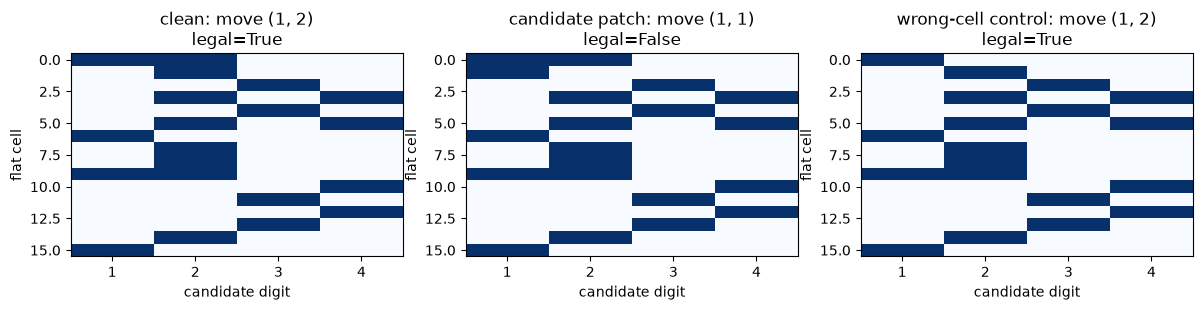

In [ ]:
recipient=solved.copy();recipient[0,1]=0
counts,_=peer_attention(clue_tokens(recipient),peers)
with t.no_grad():candidate_state=(head(counts)>0).numpy()
donor=legal_candidates(np.zeros((4,4),int))
edited=patch_candidate_state(candidate_state,donor,1,1)
wrong_cell=patch_candidate_state(candidate_state,donor,0,1)
conditions=[("clean",candidate_state),("candidate patch",edited),("wrong-cell control",wrong_cell)]
fig,axs=plt.subplots(1,3,figsize=(12,3.2))
for ax,(name,candidate) in zip(axs,conditions):
    move=naked_single_move(candidate,recipient);result=apply_move(recipient,move)
    ax.imshow(candidate.astype(int),aspect="auto",cmap="Blues",vmin=0,vmax=1)
    ax.set(xticks=range(4),xticklabels=[1,2,3,4],xlabel="candidate digit",ylabel="flat cell",title=f"{name}: move {move}\nlegal={valid_partial(result)}")
    print(name,"move",move,"legal",valid_partial(result))
fig.tight_layout();plt.show()
check_exact=candidate_agreement(predicted.numpy().reshape(-1,4),check_targets.numpy().reshape(-1,4),check_blanks.numpy().reshape(-1))
print("changed-mask exact candidate-set agreement:",check_exact)

## Try it yourself

Change the donor digit from 1 to 3. Predict which row/column/box will reject it. Then remove additional clues from the recipient until no naked singles remain. Does a stall imply no solution? Use the exact solver to answer that question, preserving the stalled model trajectory.

In [ ]:
play=solved.copy();play[[0,1,2,3],[0,1,2,3]]=0
play_states,play_moves=solve_by_head(play,head)
print("play moves:",play_moves)
print("play remaining blanks:",int((play_states[-1]==0).sum()))
print("play completion exists:",solve_exact(play) is not None)

## Interpreting the result

The fixed CPU fit reduces BCE from `0.693147` to `0.050784`; candidate-bit and exact-set check accuracies are both `1.0` on the public changed-mask orbit. The fitted head fills all eight blanks in the cold-open puzzle; the untrained control leaves eight. The clean forced move is digit 2. The donor candidate edit forces digit 1 and violates the original puzzle. A patch to a filled wrong cell is ignored by the move policy. These outcomes locate the causal dependence at the visible candidate-to-move interface. Exact candidate-set accuracy is stricter than bit accuracy; inspect both before describing the learned readout as correct.

## Limitations

This study edition implements 4×4 constraint tokenization, masked attention, a learned candidate readout, naked-single rollouts, candidate probes, causal edits and independent legality/search checks. It does **not** establish unconstrained transformer discovery of Sudoku, arbitrary multi-step search, transfer to 9×9 or a naturally emergent naked-single circuit. The geometry is supplied, readout labels come from the visible local-rule oracle, and the finite digit-permutation fitting/check orbit is public. Full small-transformer solving and circuit discovery remain pending native work.

# ☆ Bonus

**Anomaly hunt:** test an all-blank board. Candidate prediction is easy and complete, yet the naked-single policy cannot move. Explain why better candidate accuracy does not imply better puzzle completion. Contrast a globally unsatisfiable partial board with one that is merely beyond this policy.

**Changed-condition prediction:** replace the 2×2 box rule with a row/column-only Latin square rule. Predict which peer edges and candidate sets change before rebuilding the mask. Reusing the old mask is a genuine task mismatch, not a harmless model hyperparameter change.

## Further Reading

- [Transformers Linearly Represent Highly Structured World Models](https://arxiv.org/abs/2605.18847): an 8-layer transformer trained on Sudoku traces is analyzed for substructure representations and a naked-single circuit. Our supplied peer graph and explicit candidate interface are a teaching contrast, not a reproduction of that emergent circuit.
- [Recurrent Relational Networks](https://arxiv.org/abs/1711.08028): learned relational message passing for tasks including Sudoku. Our fixed peer-attention prior is a transparent contrast, not that architecture's reproduction.
- [The Annotated Transformer](https://nlp.seas.harvard.edu/annotated-transformer/): masked scaled dot-product attention and the distinction between the attention pattern and value path.
- [SATNet](https://arxiv.org/abs/1905.12149): a different way of integrating satisfiability structure with neural learning; compare a learned constraint module with the exact rules supplied here.